---
title: "Figures: Investment and Capital Market Imperfections"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Open this notebook in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/investment/DynanImperfCapMkts/DynanImperfCapMkts.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/investment/DynanImperfCapMkts/DynanImperfCapMkts.ipynb).

In [the chapter's model](https://intertemporal-choice.github.io/content/investment/dynanimperfcapmkts), external finance carries a premium that rises with the borrower's risk and falls with its net worth, so it should widen in recessions, when net worth falls. One measure of it with a long history is the spread between the yields on corporate bonds of lower and higher credit quality.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
import os

import pandas as pd
import matplotlib.pyplot as plt

from intertemporal_choice import spreads, style

style.use_book_style()

## The data

Three monthly series from [FRED](https://fred.stlouisfed.org): Moody's yields on seasoned corporate bonds rated Baa ([`BAA`](https://fred.stlouisfed.org/series/BAA)) and Aaa ([`AAA`](https://fred.stlouisfed.org/series/AAA)), in percent a year, from 1919; and the NBER's recession dates ([`USREC`](https://fred.stlouisfed.org/series/USREC)). The copies in `data/` were downloaded from FRED on 2026-10-31, so the numbers here don't change when FRED's do. Set `REFRESH = True` to use the latest data instead.

In [ ]:
REFRESH = False  # True: download the latest data from FRED instead of the copies made on 2026-10-31
FRED = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="
BOOK = "https://raw.githubusercontent.com/intertemporal-choice/intertemporal-choice.github.io/main/content/investment/DynanImperfCapMkts/data/"
copies = "data/" if os.path.isdir("data") else BOOK  # BOOK when the notebook runs on its own, as in Colab


def load(series):
    """A monthly FRED series, indexed by month."""
    path = FRED + series if REFRESH else copies + series + ".csv"
    return pd.read_csv(path, comment="#", index_col=0, parse_dates=True, na_values=".")[series].dropna()


spread = (load("BAA") - load("AAA")).dropna()  # percentage points
recessions = load("USREC")

## The spread

The spread's highest values in three episodes, and its average in recessions and in expansions:

In [ ]:
episodes = {"Great Depression": ("1929", "1934"), "financial crisis": ("2007", "2010"), "pandemic": ("2020", "2020")}
peaks = {name: spread.loc[a:b].idxmax() for name, (a, b) in episodes.items()}
for name, date in peaks.items():
    print(f"{name}: highest {spread[date]:.2f} points, {date:%B %Y}")
both = pd.concat([spread, recessions], axis=1, sort=True).dropna()
print(f"average {both[both.iloc[:, 1] == 1].iloc[:, 0].mean():.2f} points in recessions, "
      f"{both[both.iloc[:, 1] == 0].iloc[:, 0].mean():.2f} in expansions, {spread.index[0]:%Y} to {spread.index[-1]:%Y}")

Great Depression: highest 5.64 points, May 1932
financial crisis: highest 3.38 points, December 2008
pandemic: highest 1.70 points, April 2020
average 1.72 points in recessions, 1.03 in expansions, 1919 to 2026


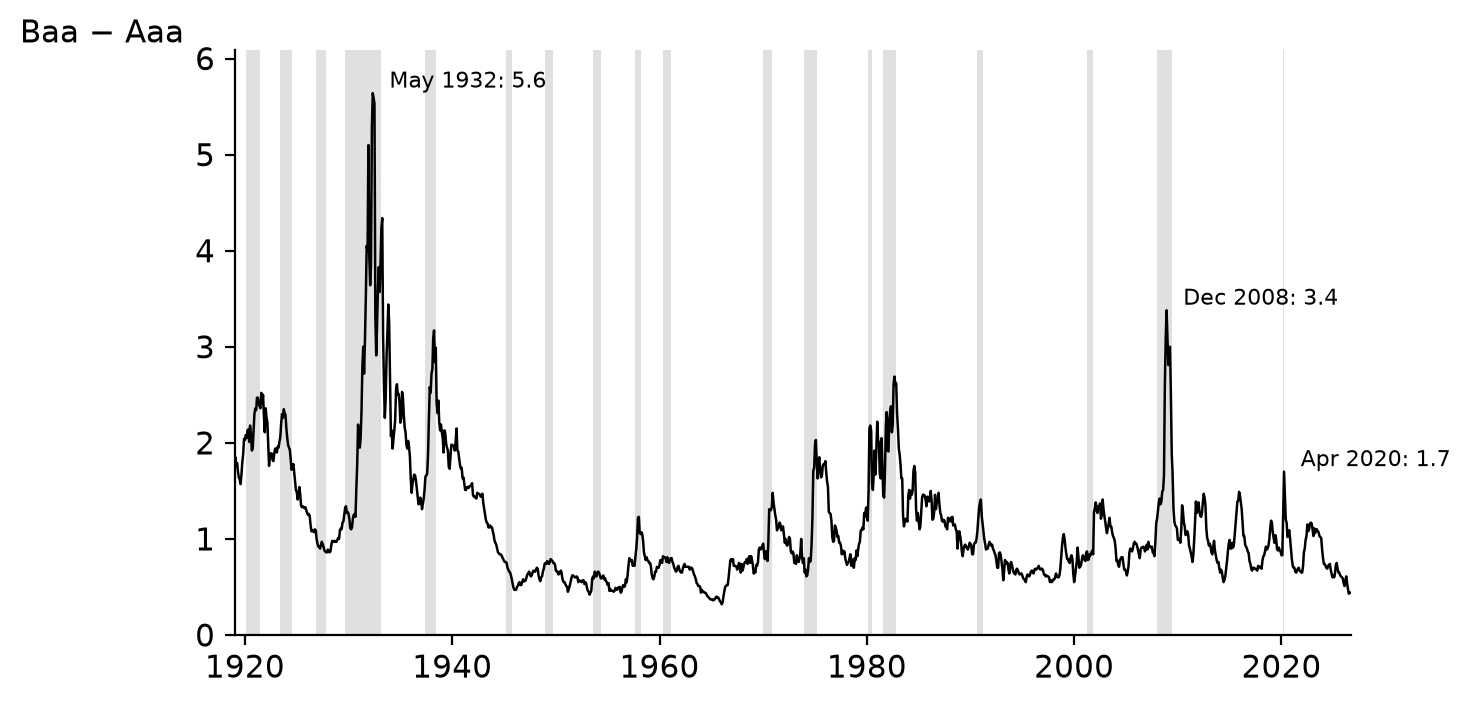

In [ ]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
spreads.draw_spread(ax, spread, recessions, marks=list(peaks.values()))
style.save(fig, "CreditSpread")

## The chapter's results

In [ ]:
inside = both[both.iloc[:, 1] == 1].iloc[:, 0].mean()
outside = both[both.iloc[:, 1] == 0].iloc[:, 0].mean()
assert inside > outside  # wider in recessions
assert spread[peaks["Great Depression"]] > spread[peaks["financial crisis"]] > spread[peaks["pandemic"]]